# Homework 6

TFCB 2024

Due date: Nov 14, 2024

In this homework, we will work through a series of manipulations to analyze a published deep sequencing
dataset using `tidyverse` functions.

In the process, we will learn some new functions in `tidyverse` and apply
them to our data analysis.

For more information about the data used in this homework, see
[this page](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE89183).


In [20]:
library(tidyverse)

## Problem 1

**10 points**

For each of the following functions, provide a <100 character description
(in your own words) and a URL reference.

1. `!`
1. `colnames()`
2. `is.na`
3. `is.numeric`
4. `anti_join`
5. `desc`
6. `dplyr::slice`
7. `dplyr::across`

| Function or operator | Description (under 100 characters) | URL reference |
|---|---|---|
| `!` | Flips `TRUE` to `FALSE` and `FALSE` to `TRUE`. | [R logical operators](https://stat.ethz.ch/R-manual/R-devel/library/base/html/Logic.html) [stat.ethz.ch](https://stat.ethz.ch/R-manual/R-devel/library/base/html/Logic.html?utm_source=chatgpt.com) |
| `colnames()` | Reads or sets the column names of a matrix or data frame. | [R column names](https://stat.ethz.ch/R-manual/R-devel/library/base/html/colnames.html) [stat.ethz.ch](https://stat.ethz.ch/R-manual/R-devel/library/base/html/colnames.html?utm_source=chatgpt.com) |
| `is.na()` | Returns `TRUE` for each missing value and `FALSE` for each observed value. | [R missing values](https://stat.ethz.ch/R-manual/R-devel/library/base/html/NA.html) [stat.ethz.ch](https://stat.ethz.ch/R-manual/R-devel/library/base/html/NA.html?utm_source=chatgpt.com) |
| `is.numeric()` | Checks whether R treats an object as numeric. | [R numeric vectors](https://stat.ethz.ch/R-manual/R-devel/library/base/html/numeric.html) [stat.ethz.ch](https://stat.ethz.ch/R-manual/R-devel/library/base/html/numeric.html?utm_source=chatgpt.com) |
| `anti_join()` | Keeps rows from the first table that have no match in the second table. | [dplyr filtering joins](https://dplyr.tidyverse.org/reference/filter-joins.html) [filter-joins • dplyr](https://dplyr.tidyverse.org/reference/filter-joins.html?utm_source=chatgpt.com) |
| `desc()` | Tells `arrange()` to sort a column in descending order. | [dplyr descending order](https://dplyr.tidyverse.org/reference/desc.html) [desc • dplyr](https://dplyr.tidyverse.org/reference/desc.html?utm_source=chatgpt.com) |
| `dplyr::slice()` | Selects rows by position, using positive numbers to keep rows or negative numbers to drop them. | [dplyr slice](https://dplyr.tidyverse.org/reference/slice.html) [slice • dplyr](https://dplyr.tidyverse.org/reference/slice.html?utm_source=chatgpt.com) |
| `dplyr::across()` | Applies one or more functions to each selected column. | [dplyr across](https://dplyr.tidyverse.org/reference/across.html) [across • dplyr](https://dplyr.tidyverse.org/reference/across.html?utm_source=chatgpt.com) |


## Problem 2

**10 points**

Add a comment above each code line below explaining what the code line does and/or why
that code line is necessary.

Keep each comment to less than 2 lines per line of code and < 80 chars per line.

In [21]:
library(biomaRt)

# Try with explicit host and archive version
tryCatch({
  mart <- useMart('ensembl', dataset = 'hsapiens_gene_ensembl', 
                  host = "https://may2015.archive.ensembl.org")
}, error = function(e) {
  cat("Could not connect to Ensembl. Trying alternative host...\n")
  mart <<- useMart('ensembl', dataset = 'hsapiens_gene_ensembl',
                   host = "https://www.ensembl.org")
})

# Retrieve annotations
annotations <- getBM(
  mart = mart,
  attributes = c('ensembl_gene_id', 'hgnc_symbol', 'ccds'),
  uniqueRows = TRUE) %>%
  rename(ccds_id = `ccds`) %>%
  filter(ccds_id != '') %>%
  print()

Ensembl site unresponsive, trying uswest mirror



Could not connect to Ensembl. Trying alternative host...


ERROR: Error in bmRequest(request = request, httr_config = httr_config, verbose = verbose): Not Found (HTTP 404).


In [ ]:
# bring in library for biomaRt 
library(biomaRt)
# connect to Ensembl BioMart for human genes
mart <- useMart('ensembl', dataset = 'hsapiens_gene_ensembl')
#mart <- useDataset(“hsapiens_gene_ensembl”, mart)
# retrieve annotations for Ensembl gene IDs, HGNC symbols, and CCDS IDs
annotations <- getBM(
  mart = mart,
  attributes = c('ensembl_gene_id', 'hgnc_symbol', 'ccds'),
  uniqueRows = TRUE) %>%
  rename(ccds_id = `ccds`) %>%
  filter(ccds_id != '') %>%
  print()

ERROR: Error in bmRequest(request = request, httr_config = httr_config, verbose = verbose): Not Found (HTTP 404).


In [ ]:


data <- read_tsv("/workspaces/tfcb_2026/homeworks/homework06/GSE89183_Counts.txt") %>%
  rename(ensembl_gene_id = `ENSEMBL gene`) %>%
  print()

Rows: 63677 Columns: 15
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (1): ENSEMBL gene
dbl (14): CD34_shTSR2_RNA_1, CD34_shTSR2_RNA_2, CD34_shRPL5_RNA_1, CD34_shRP...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 63,677 × 15
   ensembl_gene_id CD34_shTSR2_RNA_1 CD34_shTSR2_RNA_2 CD34_shRPL5_RNA_1
   <chr>                       <dbl>             <dbl>             <dbl>
 1 ENSG00000000003                48                56                40
 2 ENSG00000000005                 0                 2                 0
 3 ENSG00000000419               880               744              1116
 4 ENSG00000000457               124               113               149
 5 ENSG00000000460               249               262               289
 6 ENSG00000000938                89                64               204
 7 ENSG00000000971               106                86               241
 8 ENSG00000001036               897               613              1487
 9 ENSG00000001084               965              1027              1036
10 ENSG00000001167               721               835               498
# … with 63,667 more rows, and 11 more variables: CD34_shRPL5_RNA_2 <dbl>,
#   CD34_shRPL5_RPF_1 <db

In [ ]:
# read in GEO dataset and rename Ensembl gene ID column
data <- read_tsv("ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE89nnn/GSE89183/suppl/GSE89183_Counts.txt.gz") %>%
  rename(ensembl_gene_id = `ENSEMBL gene`) %>%
  print()

Rows: 63677 Columns: 15
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (1): ENSEMBL gene
dbl (14): CD34_shTSR2_RNA_1, CD34_shTSR2_RNA_2, CD34_shRPL5_RNA_1, CD34_shRP...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 63,677 × 15
   ensembl_gene_id CD34_shTSR2_RNA_1 CD34_shTSR2_RNA_2 CD34_shRPL5_RNA_1
   <chr>                       <dbl>             <dbl>             <dbl>
 1 ENSG00000000003                48                56                40
 2 ENSG00000000005                 0                 2                 0
 3 ENSG00000000419               880               744              1116
 4 ENSG00000000457               124               113               149
 5 ENSG00000000460               249               262               289
 6 ENSG00000000938                89                64               204
 7 ENSG00000000971               106                86               241
 8 ENSG00000001036               897               613              1487
 9 ENSG00000001084               965              1027              1036
10 ENSG00000001167               721               835               498
# … with 63,667 more rows, and 11 more variables: CD34_shRPL5_RNA_2 <dbl>,
#   CD34_shRPL5_RPF_1 <db

## Problem 3

**10 points**

Using the code below:

1. Convert both axes to `log10` instead of linear scales.
2. Show axis tick labels as 10^0^, 10^1^, 10^2^,10^3^, 10^4^, 10^5^ for both axes.
3. There are too many points overlapping in certain regions. Use a different
`geom_` function to convey to your reader how many overlapping points are present
in each region.

Warning message:
“Transformation introduced infinite values in continuous x-axis”
Warning message:
“Transformation introduced infinite values in continuous y-axis”
Warning message:
“Removed 43031 rows containing non-finite values (stat_bin2d).”


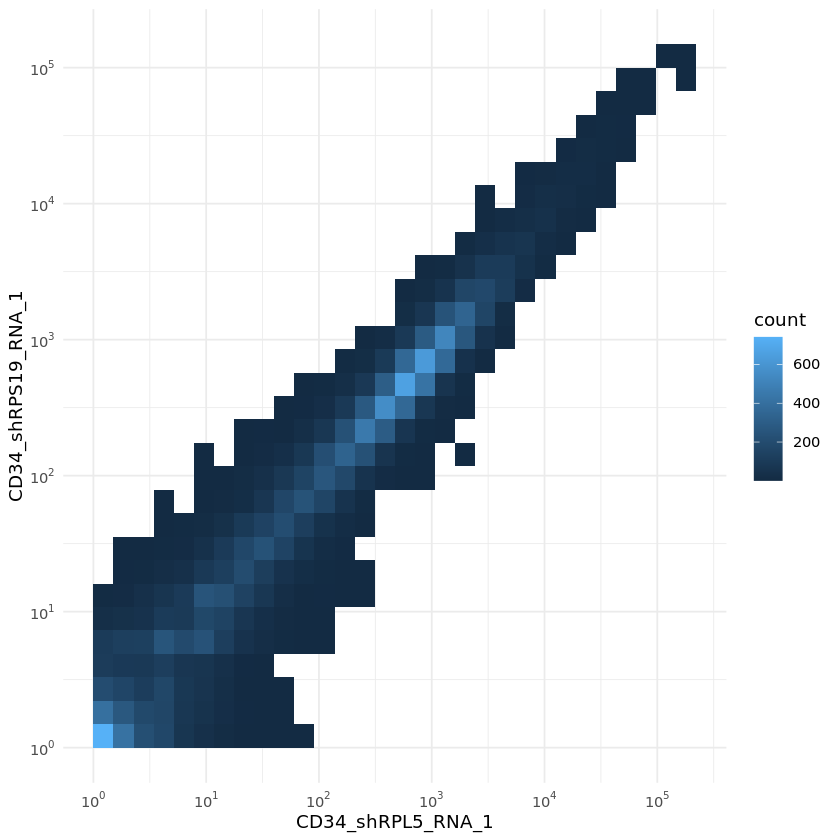

In [27]:
library(ggplot2)
library(scales)

ggplot(data, aes(x = CD34_shRPL5_RNA_1, y = CD34_shRPS19_RNA_1)) +
  geom_bin2d(bins = 30) +
  scale_x_log10(
    breaks = scales::trans_breaks("log10", function(x) 10^x),
    labels = scales::trans_format("log10", scales::math_format(10^.x))
  ) +
  scale_y_log10(
    breaks = scales::trans_breaks("log10", function(x) 10^x),
    labels = scales::trans_format("log10", scales::math_format(10^.x))
  ) +
  theme_minimal()

**In problems 4 through 6, assign the result of your operation back to the `data`
variable.**

## Problem 4

**10 points**

Write a code cell to select the following columns from the `data` variable you created above and reassign back to `data`.

Columns to select: `ensembl_gene_id`, columns that have either `RPL5`, `RPS19`, or `Luc` in their name.

Instead of listing every column, use [`matches`](https://tidyselect.r-lib.org/reference/starts_with.html) and a succinct [regular expression](https://stringr.tidyverse.org/articles/regular-expressions.html) to select the above columns.

In [ ]:
data <- data %>%
  select(ensembl_gene_id, matches("RPL5|RPS19|Luc"))

## Problem 5

**10 points**

Write a code cell to filter the result from Problem 4 to include only rows where each of the 12 numerical columns you selected has 50 counts or more  and reassign back to `data`.
This is a simple way to avoid genes that have very low counts.

You might be tempted to do this step separately for each of the 12 columns, but instead use the `across` function you learned above or the `pivot_longer` function from the class (either way is fine).

## Problem 6

**10 points**

Write a code cell to divide each of the 12 numerical columns by the
corresponding median value for each column
and reassign back to `data`. This median normalization is typically done in
high-throughput experiments after filtering
to normalize for sample-to-sample difference in read depth.

Again, you can write lot less code if you use the `mutate` and `across` function
you learned above.


## Problem 7

**10 points**

After we do the above filtering and median-normalization, let us calculate
translation efficiency as the average ratio of the RPF and RNA reads for each
treatment condition. Then we calculate how this translation efficiency changes
between target (`rpl5` and `rps19`) and control (`luc`) shRNAs.

The code implementing the above steps is shown below, but it has a few
errors. Correct them.


In [ ]:
lfc <- data %>%
  mutate(mean_rpl5_te = ((CD34_shRPL5_RPF_1 + CD34_shRPL5_RPF_2) /
                            (CD34_shRPL5_RNA_1 + CD34_shRPL5_RNA_2)) %>%
  mutate(mean_rps19_te = ((CD34_shRPS19_RPF_1 + CD34_shRPS19_RPF_2) /
                            (CD34_shRPS19_RNA_1 + CD34_shRPS19_RNA_2)) %>%
  mutate(mean_shluc_te = ((CD34_shLuc_RPF_1 + CD34_shLuc_RPF_2) /
                            (CD34_shLuc_RNA_1 + CD34_shLuc_RNA2)) %>%
  select(ensembl_gene_id, mean_rpl5_te, mean_rps19_te) %>%
  mutate(lfc_te_rpl5 == log2(mean_rpl5_te / mean_shluc_te),
         lfc_te_rps19 == log2(mean_rps19_te / mean_shluc_te)) %>%
  print()

## Problem 8

**10 points**

Write code that will create a new dataframe called `mean_lfc` from `lfc`
containing a new column called `avg_lfc`.
`avg_lfc` should be the average of the log2 fold-change in TE (`lfc_te`) upon
knockdown of RPL5 and RPS19.

Then select only the gene id column and the new column that you just created
(this will be your new dataframe `mean_lfc`).



## Problem 9

**10 points**

Write code to join the `mean_lfc` dataframe with the `annotations` dataframe created
at the top of the document and assign back to `mean_lfc`.


## Problem 10

**10 points**

1. Write code to select only the bottom 10 genes with the lowest `avg_lfc` and display the gene `symbol`, gene `name` and `avg_lfc` for these genes.
2. Create a figure using `ggplot2` to visualize these results.

Write a few sentences to justify the choices you made when creating your figure.